# Progetto d'esame: Apprendimento Automatico e Apprendimento Profondo

**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI Machine Learning Repository (ID 17)

L'obiettivo è distinguere un tumore al seno **maligno** da uno **benigno** a partire dalle misure dei nuclei cellulari ottenute da un'immagine dell'agoaspirato.

Struttura del notebook:
1. caricamento e prima esplorazione dei dati
2. suddivisione train / validation / test e standardizzazione
3. analisi delle feature con la PCA
4. tre (anzi quattro) classificatori "shallow", con scelta degli iperparametri sul validation set
5. metriche, matrici di confusione e curve ROC sul test set
6. opzione a): rete neurale sugli stessi dati e con la stessa suddivisione

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # meno messaggi da TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
os.makedirs("figure", exist_ok=True)

## 1. Caricamento dei dati

Il dataset è il n. 17 del repository UCI. scikit-learn ne include una copia identica (569 campioni, 30 feature), quindi lo carico da lì: così il notebook funziona anche senza scaricare niente.

Nel dataset originale di sklearn la classe 0 è "maligno" e la 1 è "benigno". Preferisco invertire le etichette e considerare **maligno = 1** come classe positiva, perché è quella che interessa davvero trovare: in questo modo precision e recall si riferiscono ai tumori maligni.

In [2]:
dati = load_breast_cancer(as_frame=True)
X = dati.data
y = (dati.target == 0).astype(int)   # 1 = maligno, 0 = benigno

print("Dimensioni:", X.shape)
print("Valori mancanti:", X.isna().sum().sum())
print(y.value_counts().rename({0: "benigno (0)", 1: "maligno (1)"}))
X.head()

Dimensioni: (569, 30)
Valori mancanti: 0
target
benigno (0)    357
maligno (1)    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Le 30 feature sono in realtà 10 caratteristiche del nucleo (raggio, texture, perimetro, area, smoothness, compactness, concavity, punti concavi, simmetria, dimensione frattale), ognuna riportata come media (`mean`), errore standard (`error`) e valore peggiore (`worst`).

Prima della PCA guardo quanto sono correlate tra loro le 10 feature `mean`.

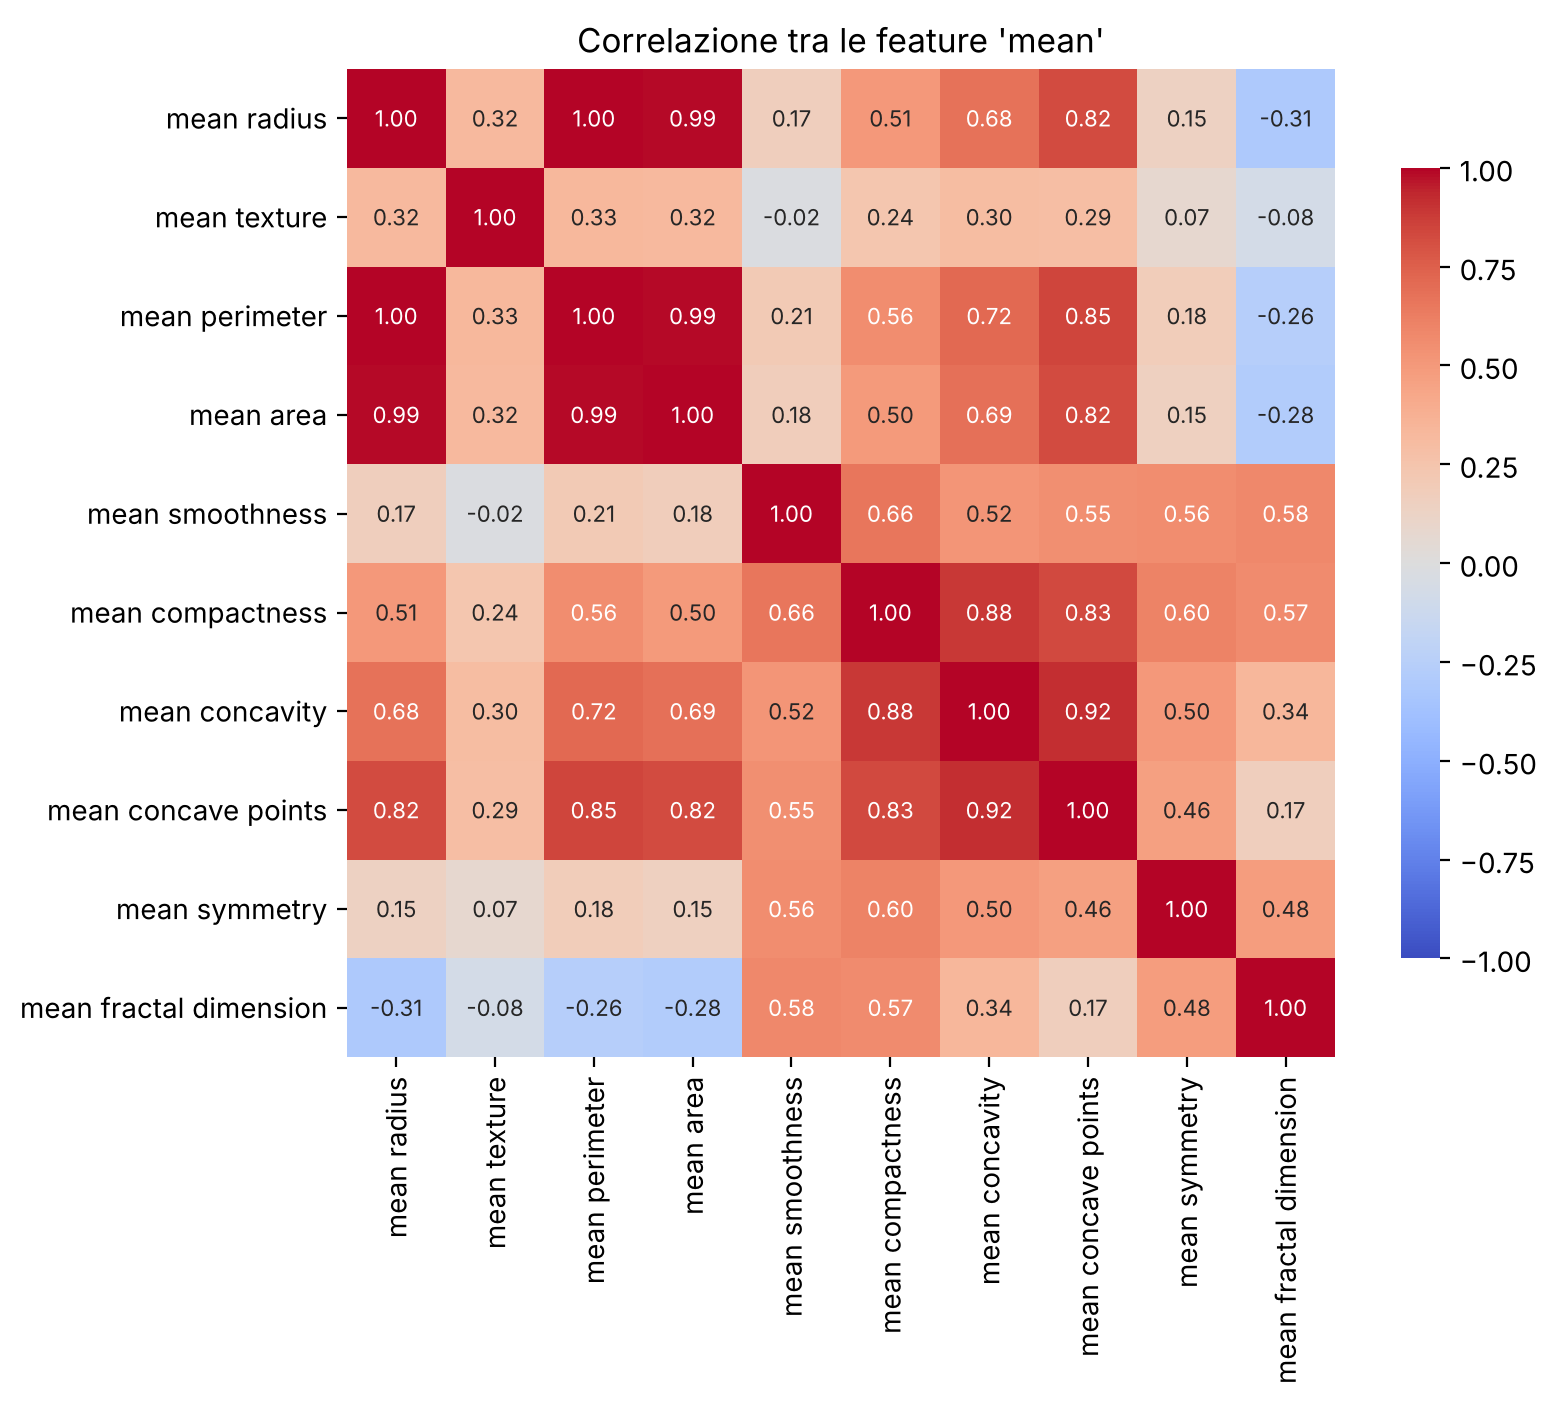

In [3]:
colonne_mean = [c for c in X.columns if c.startswith("mean")]

plt.figure(figsize=(8.5, 7))
sns.heatmap(X[colonne_mean].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.8}, annot_kws={"size": 8})
plt.title("Correlazione tra le feature 'mean'")
plt.tight_layout()
plt.savefig("figure/correlazione_mean.png", dpi=150)
plt.show()

Raggio, perimetro e area sono correlati quasi al 100% (ovvio, sono legati geometricamente), e anche concavity, compactness e punti concavi vanno molto insieme. C'è parecchia informazione ripetuta, quindi la PCA dovrebbe riuscire a comprimere bene.

## 2. Train / validation / test

Uso 60% / 20% / 20%, stratificando sulla classe. La stessa suddivisione la riuso identica per la rete neurale. Lo scaler viene stimato **solo sul training set** e poi applicato a validation e test.

In [4]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)   # 0.25 * 0.8 = 0.2

for nome, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{nome:10s} {len(yy):4d} campioni, di cui maligni {yy.sum():3d} ({yy.mean():.1%})")

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

train       341 campioni, di cui maligni 127 (37.2%)
validation  114 campioni, di cui maligni  43 (37.7%)
test        114 campioni, di cui maligni  42 (36.8%)


## 3. Analisi delle feature con la PCA

Per essere sicuro di aver capito cosa fa, prima la scrivo a mano con numpy (autovalori e autovettori della matrice di covarianza dei dati standardizzati) e poi controllo che il risultato coincida con `sklearn.decomposition.PCA`.

In [5]:
# PCA "a mano"
cov = np.cov(X_train_s, rowvar=False)
autovalori, autovettori = np.linalg.eigh(cov)      # eigh perché la covarianza è simmetrica
ordine = np.argsort(autovalori)[::-1]               # dal più grande al più piccolo
autovalori, autovettori = autovalori[ordine], autovettori[:, ordine]
var_spiegata = autovalori / autovalori.sum()

# confronto con scikit-learn
pca = PCA().fit(X_train_s)
diff = np.abs(var_spiegata - pca.explained_variance_ratio_).max()
print("Differenza massima con sklearn:", diff)

cumulata = np.cumsum(var_spiegata)
n95 = int(np.argmax(cumulata >= 0.95) + 1)
print("Varianza spiegata dalle prime 5 componenti:", np.round(var_spiegata[:5], 3))
print(f"PC1 + PC2 = {cumulata[1]:.1%}")
print("Componenti necessarie per il 95% della varianza:", n95)

Differenza massima con sklearn: 8.798470036309319e-17
Varianza spiegata dalle prime 5 componenti: [0.456 0.182 0.094 0.065 0.055]
PC1 + PC2 = 63.8%
Componenti necessarie per il 95% della varianza: 10


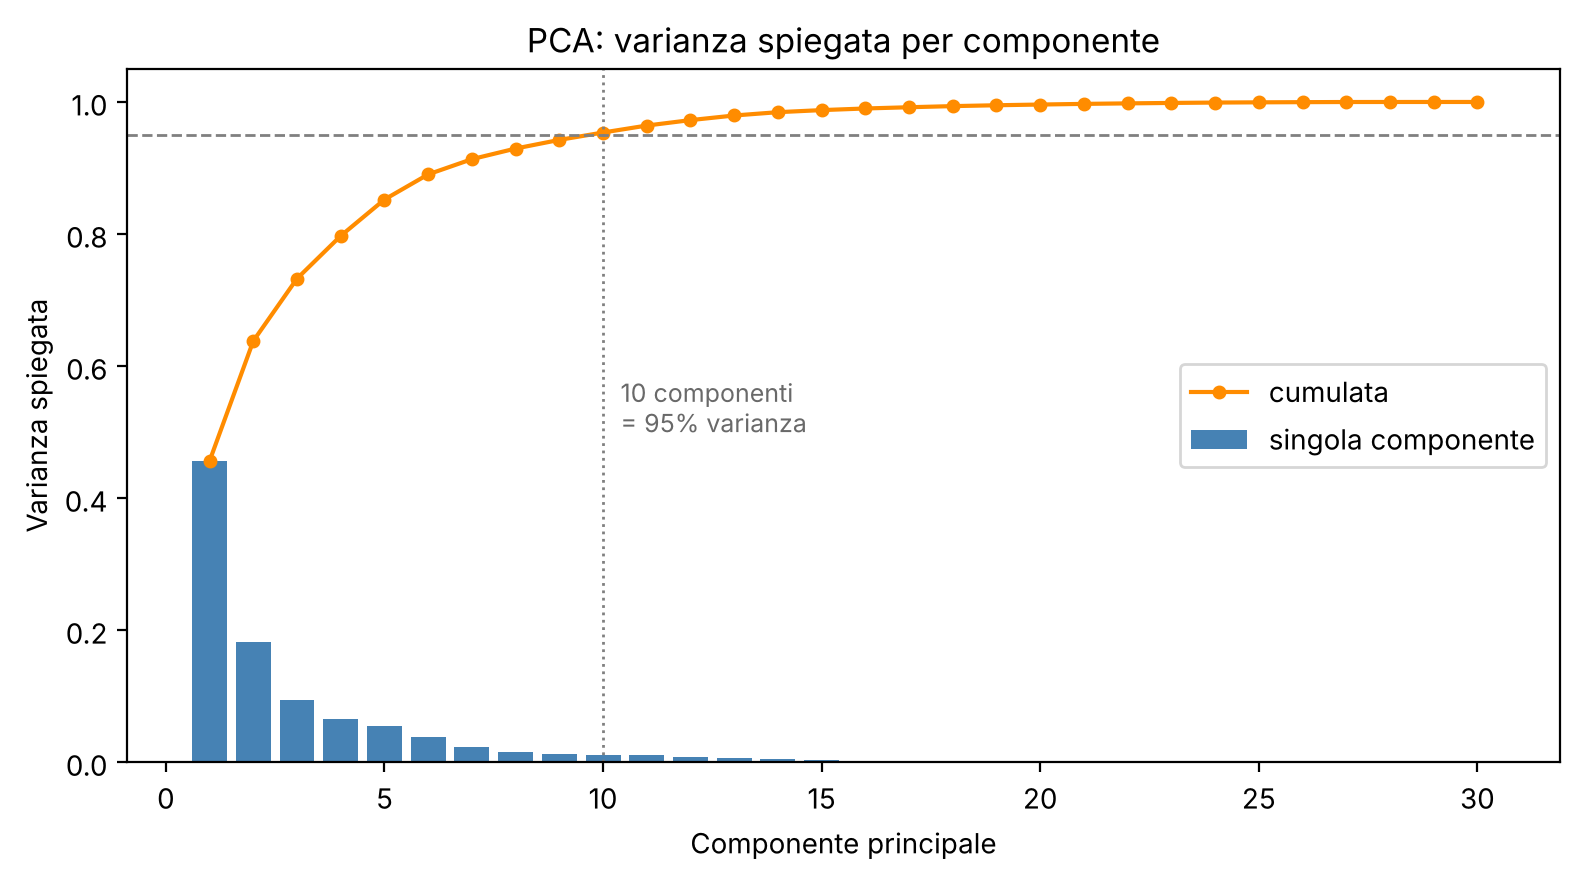

In [6]:
k = np.arange(1, len(var_spiegata) + 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(k, var_spiegata, color="steelblue", label="singola componente")
ax.plot(k, cumulata, "o-", color="darkorange", ms=4, label="cumulata")
ax.axhline(0.95, ls="--", color="grey", lw=1)
ax.axvline(n95, ls=":", color="grey", lw=1)
ax.text(n95 + 0.4, 0.5, f"{n95} componenti\n= 95% varianza", color="dimgrey", fontsize=9)
ax.set_xlabel("Componente principale")
ax.set_ylabel("Varianza spiegata")
ax.set_title("PCA: varianza spiegata per componente")
ax.legend(loc="center right")
plt.tight_layout()
plt.savefig("figure/pca_varianza.png", dpi=150)
plt.show()

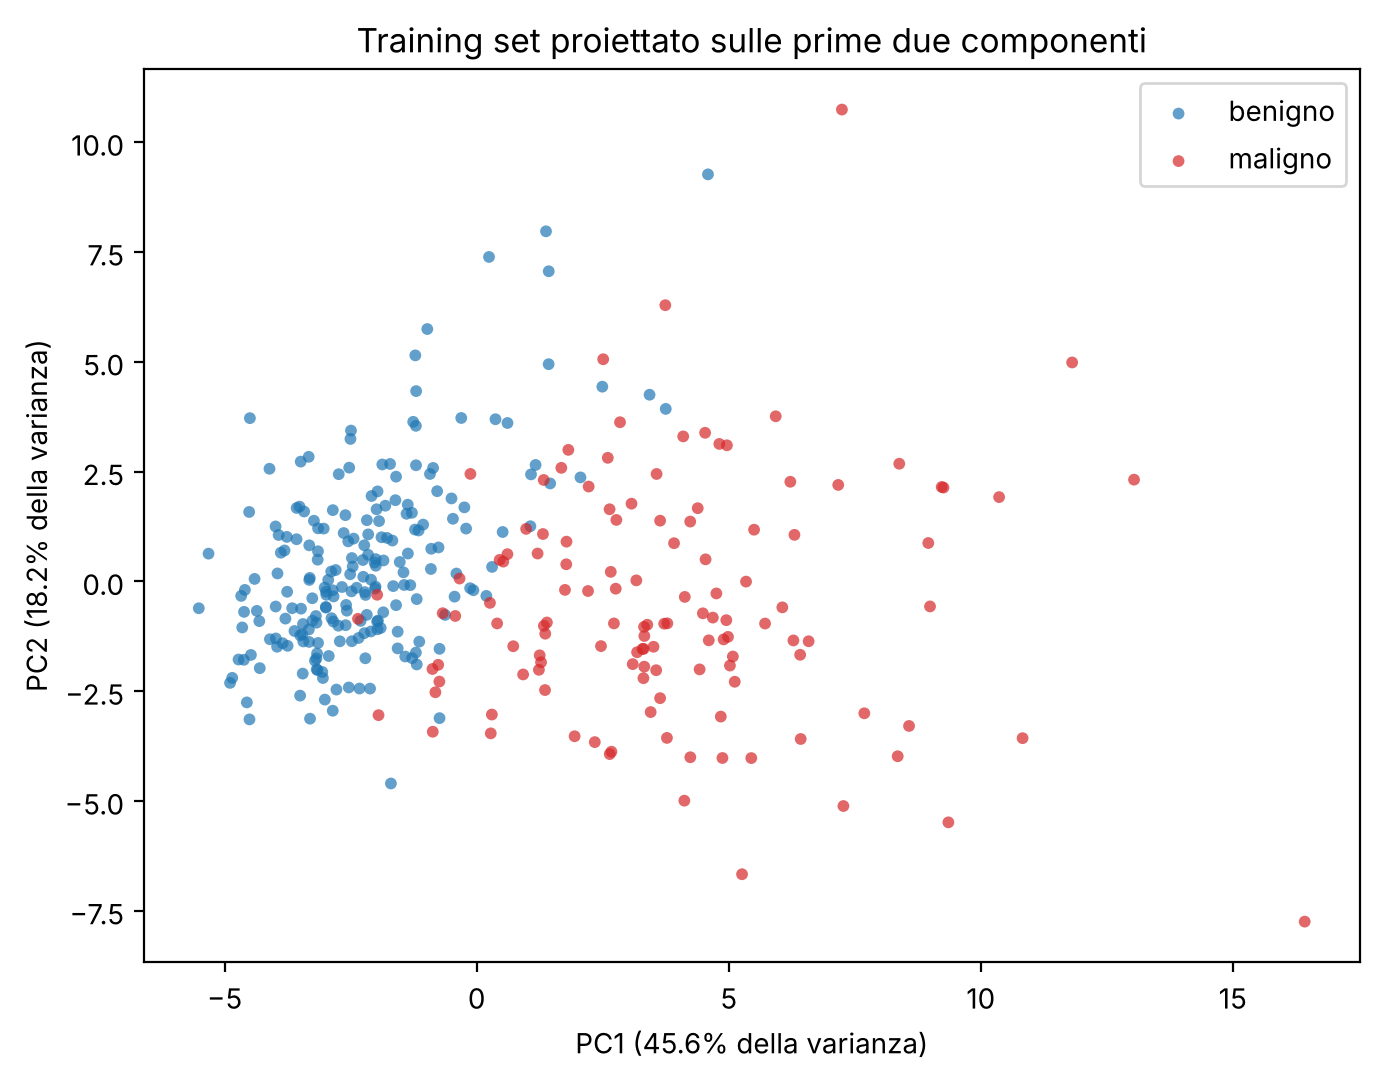

In [7]:
# da qui in poi uso la PCA di sklearn, che è la stessa cosa ma più comoda
Z = pca.transform(X_train_s)

fig, ax = plt.subplots(figsize=(7, 5.5))
for classe, colore, etichetta in [(0, "tab:blue", "benigno"), (1, "tab:red", "maligno")]:
    m = y_train.values == classe
    ax.scatter(Z[m, 0], Z[m, 1], s=18, alpha=0.7, c=colore, label=etichetta, edgecolors="none")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} della varianza)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} della varianza)")
ax.set_title("Training set proiettato sulle prime due componenti")
ax.legend()
plt.tight_layout()
plt.savefig("figure/pca_scatter.png", dpi=150)
plt.show()

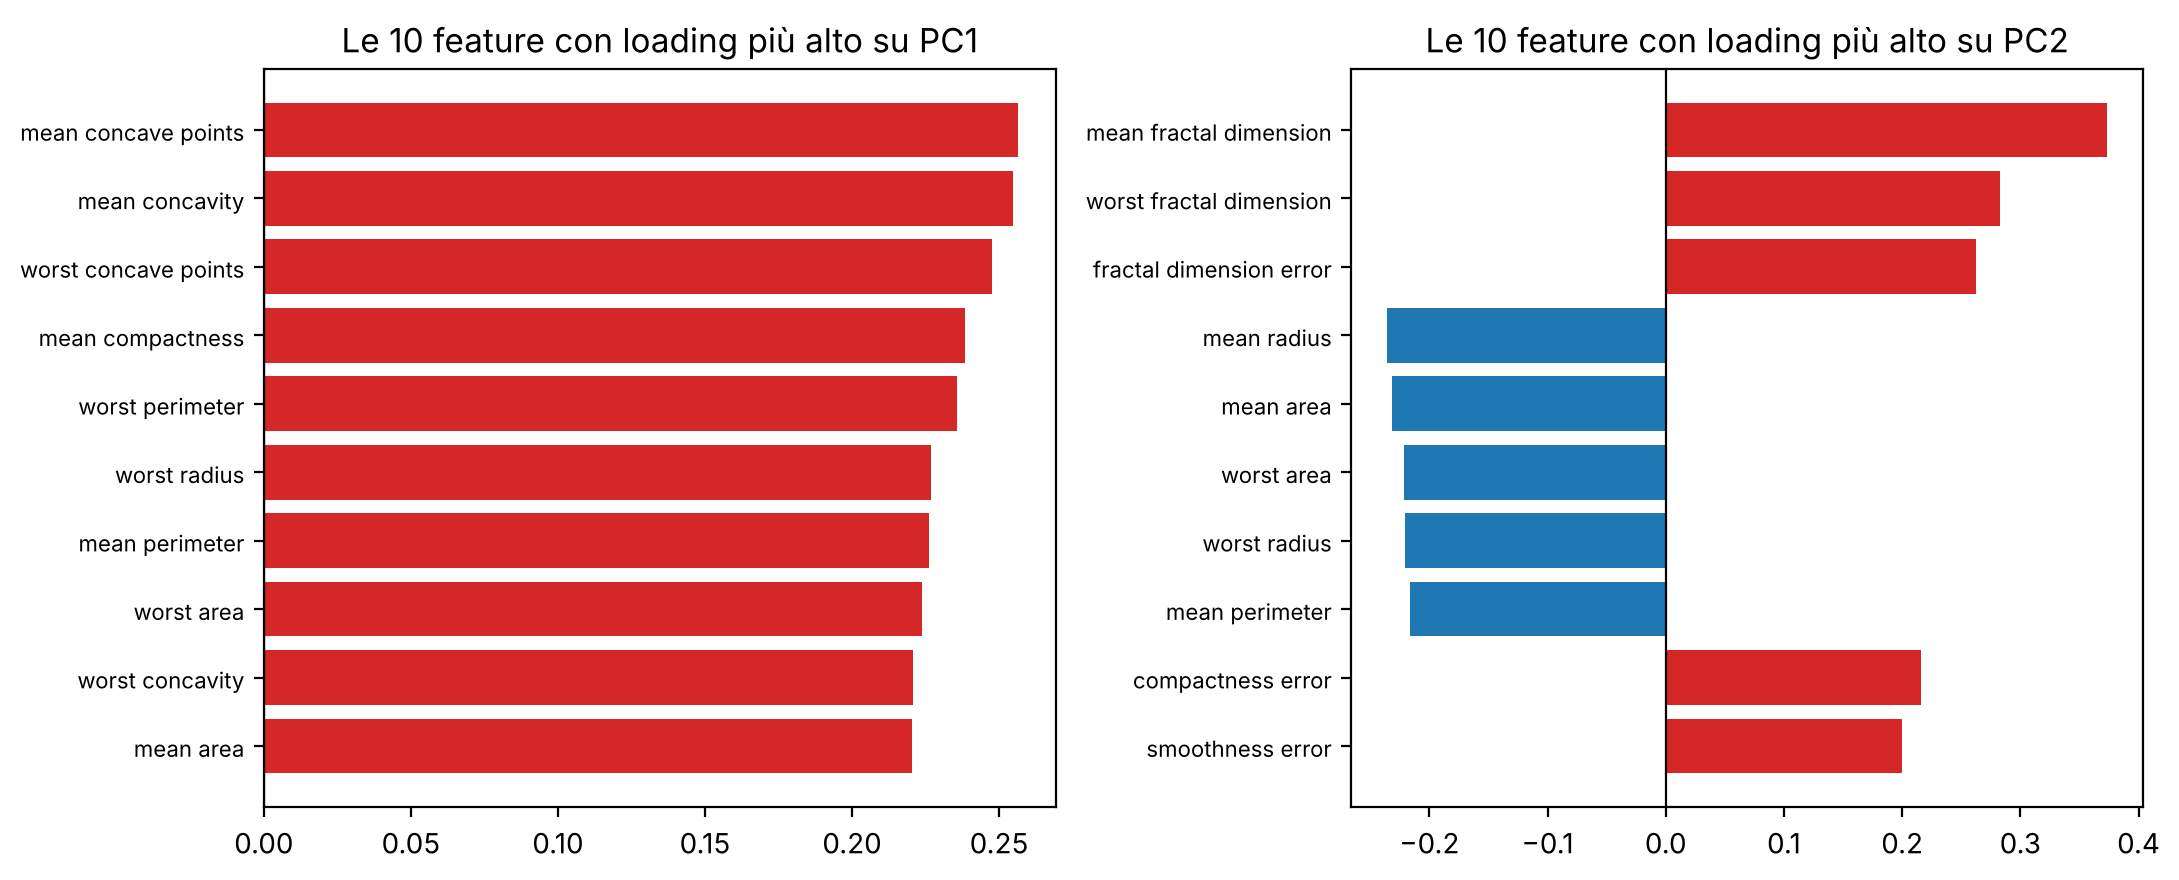

mean concave points     0.256
mean concavity          0.255
worst concave points    0.247
mean compactness        0.239
worst perimeter         0.236
Name: PC1, dtype: float64
mean fractal dimension     0.373
worst fractal dimension    0.283
fractal dimension error    0.263
mean radius                0.236
mean area                  0.232
Name: PC2, dtype: float64


In [8]:
# quali feature pesano di più sulle prime due componenti?
loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(10)
    colori = ["tab:red" if v > 0 else "tab:blue" for v in top.values]
    ax.barh(top.index[::-1], top.values[::-1], color=colori[::-1])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Le 10 feature con loading più alto su {pc}")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig("figure/pca_loadings.png", dpi=150)
plt.show()

print(loadings["PC1"].abs().sort_values(ascending=False).head(5).round(3))
print(loadings["PC2"].abs().sort_values(ascending=False).head(5).round(3))

Curiosità: quanto perde un modello semplice (regressione logistica) se invece delle 30 feature gli do solo le prime *k* componenti principali? Lo misuro sul validation set.

In [9]:
for n in sorted({1, 2, 3, 5, n95, 30}):
    p = PCA(n_components=n).fit(X_train_s)
    lr = LogisticRegression(max_iter=5000).fit(p.transform(X_train_s), y_train)
    acc = accuracy_score(y_val, lr.predict(p.transform(X_val_s)))
    print(f"k = {n:2d} componenti  ->  accuracy sul validation = {acc:.3f}")

k =  1 componenti  ->  accuracy sul validation = 0.921
k =  2 componenti  ->  accuracy sul validation = 0.956
k =  3 componenti  ->  accuracy sul validation = 0.965
k =  5 componenti  ->  accuracy sul validation = 0.974
k = 10 componenti  ->  accuracy sul validation = 0.974
k = 30 componenti  ->  accuracy sul validation = 0.974


## 4. Classificatori

Ne ho scelti quattro tra quelli visti nel corso, abbastanza diversi tra loro:
- **Regressione logistica**: modello lineare, è il riferimento più semplice;
- **K-Nearest Neighbors**: si basa sulle distanze, quindi beneficia della standardizzazione;
- **SVM con kernel RBF**: confine di decisione non lineare;
- **Random Forest**: ensemble di alberi, non ha bisogno di scaling ma lo lascio per uniformità.

Gli iperparametri li scelgo con una piccola griglia, addestrando sul train e valutando sul validation (criterio: F1 sulla classe maligna, a parità di F1 la ROC AUC). Il test set lo uso solo alla fine.

In [10]:
def score_positivo(modello, X):
    # probabilità della classe "maligno" se il modello la fornisce,
    # altrimenti il valore della decision function (per la SVM)
    if hasattr(modello, "predict_proba"):
        return modello.predict_proba(X)[:, 1]
    return modello.decision_function(X)


griglie = {
    "Regressione logistica": [LogisticRegression(C=c, max_iter=5000)
                              for c in [0.01, 0.1, 1, 10, 100]],
    "KNN": [KNeighborsClassifier(n_neighbors=n) for n in [1, 3, 5, 7, 9, 11, 15, 21]],
    "SVM (RBF)": [SVC(C=c, gamma=g, random_state=SEED)
                  for c in [0.1, 1, 10, 100] for g in ["scale", 0.01, 0.1]],
    "Random Forest": [RandomForestClassifier(n_estimators=n, max_depth=d, random_state=SEED)
                      for n in [100, 300] for d in [None, 5, 10]],
}

migliori = {}
for nome, candidati in griglie.items():
    risultati = []
    for m in candidati:
        m.fit(X_train_s, y_train)
        f1 = f1_score(y_val, m.predict(X_val_s))
        auc = roc_auc_score(y_val, score_positivo(m, X_val_s))
        risultati.append((f1, auc, m))
    f1, auc, scelto = max(risultati, key=lambda r: (r[0], r[1]))
    migliori[nome] = scelto
    print(f"{nome:22s} F1 val = {f1:.3f}   AUC val = {auc:.3f}   ->  {scelto}")

Regressione logistica  F1 val = 0.976   AUC val = 0.995   ->  LogisticRegression(C=0.1, max_iter=5000)
KNN                    F1 val = 0.964   AUC val = 0.996   ->  KNeighborsClassifier(n_neighbors=7)
SVM (RBF)              F1 val = 0.977   AUC val = 0.996   ->  SVC(C=1, random_state=42)


Random Forest          F1 val = 0.965   AUC val = 0.992   ->  RandomForestClassifier(max_depth=5, random_state=42)


## 5. Valutazione sul test set

In [11]:
def valuta(y_vero, y_pred, y_score):
    return {"Accuracy": accuracy_score(y_vero, y_pred),
            "Precision": precision_score(y_vero, y_pred),
            "Recall": recall_score(y_vero, y_pred),
            "F1": f1_score(y_vero, y_pred),
            "ROC AUC": roc_auc_score(y_vero, y_score)}

risultati_test = {}
for nome, m in migliori.items():
    risultati_test[nome] = valuta(y_test, m.predict(X_test_s), score_positivo(m, X_test_s))

pd.DataFrame(risultati_test).T.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC
Regressione logistica,0.982,1.000,0.952,0.976,0.998
KNN,0.947,0.974,0.881,0.925,0.984
SVM (RBF),0.974,0.976,0.952,0.964,0.994
Random Forest,0.956,0.974,0.905,0.938,0.997


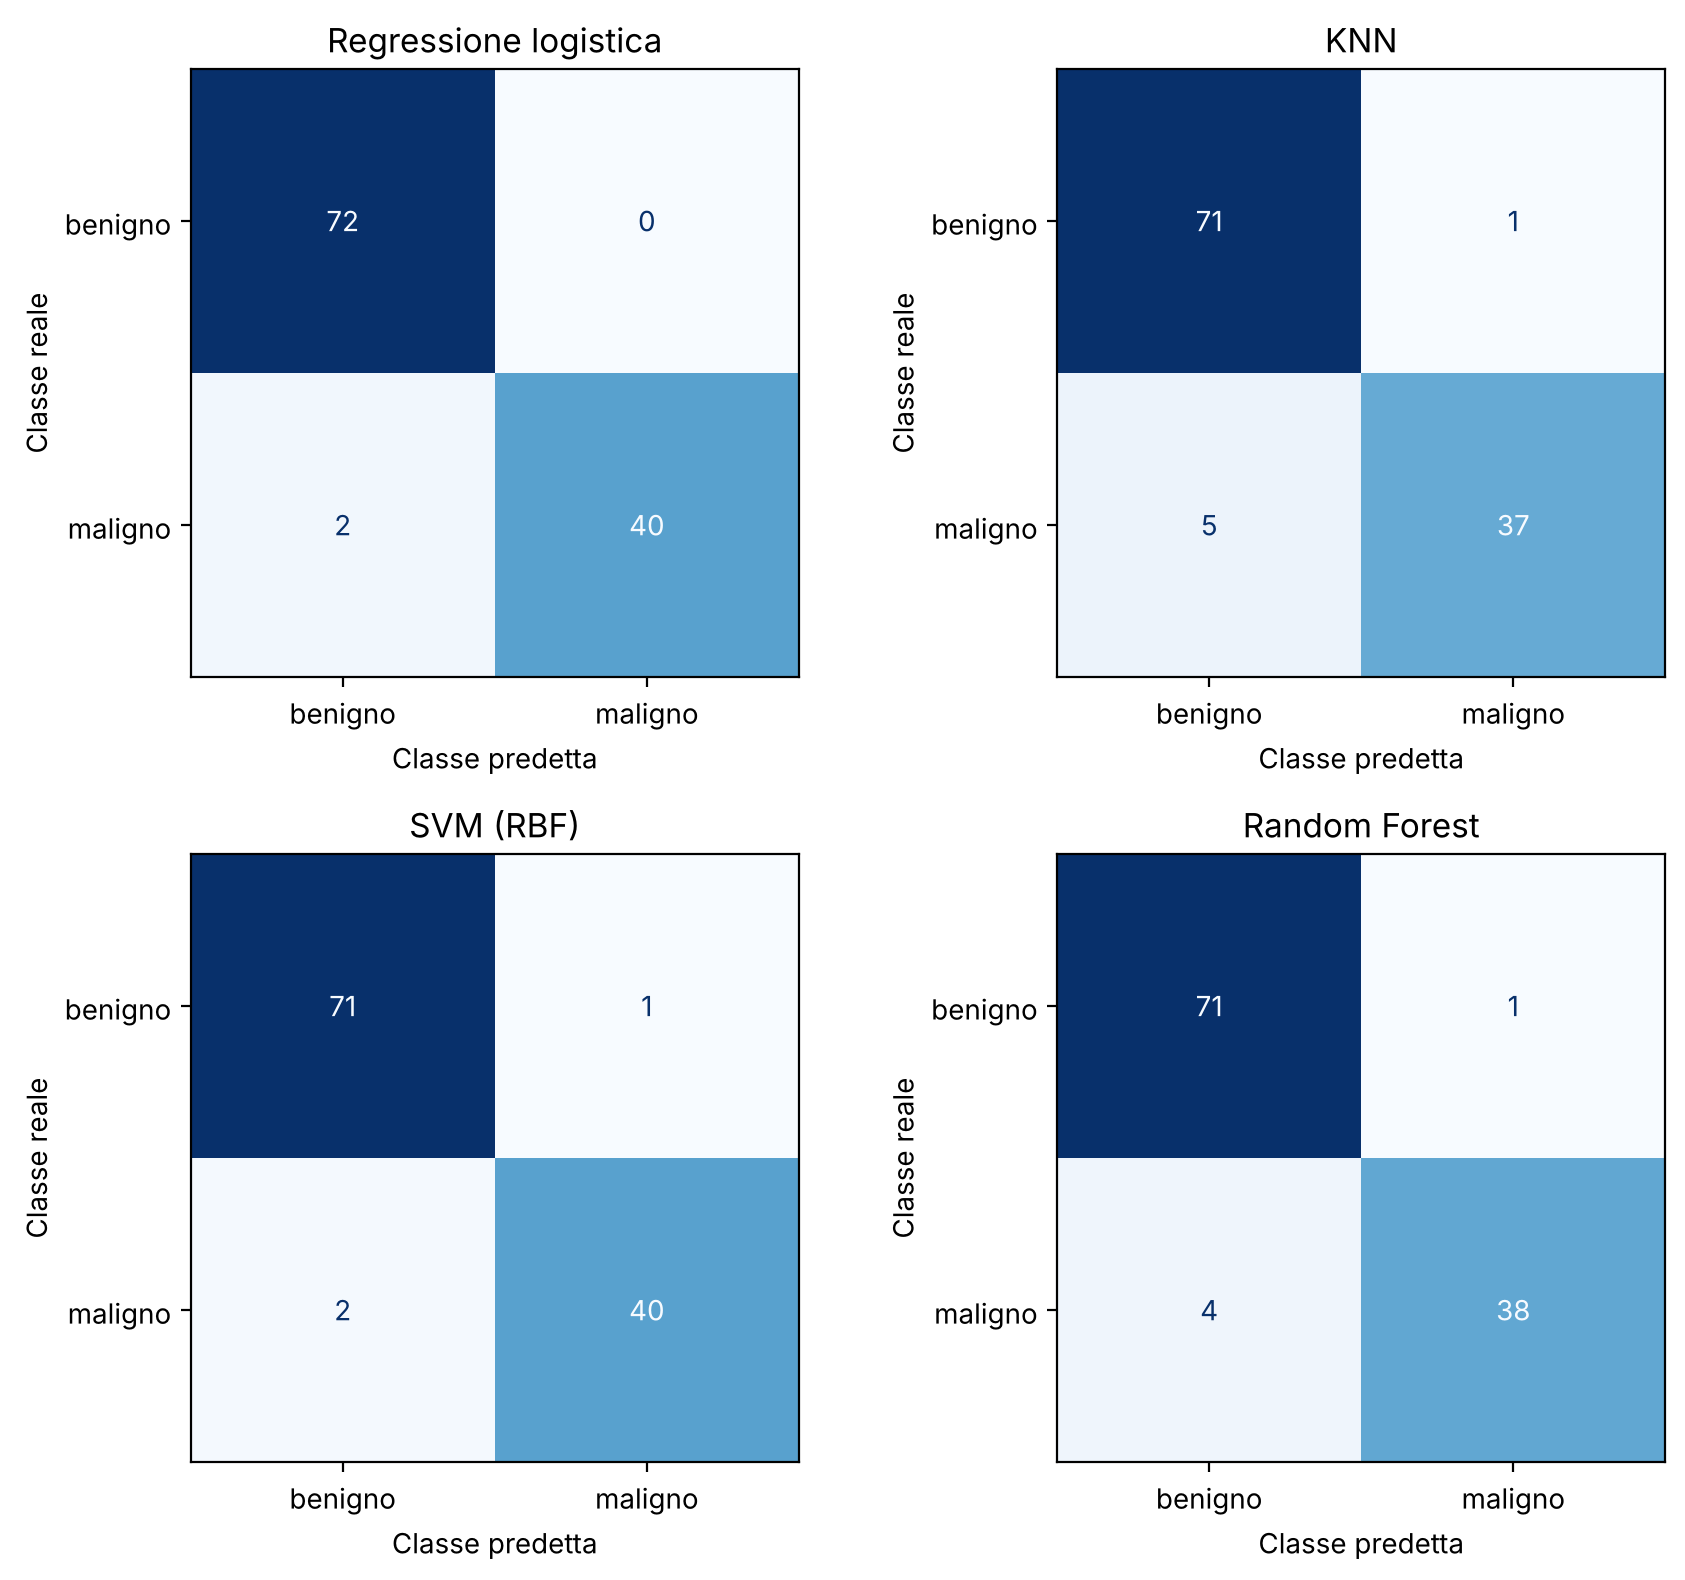

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (nome, m) in zip(axes.ravel(), migliori.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, m.predict(X_test_s), display_labels=["benigno", "maligno"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nome)
    ax.set_xlabel("Classe predetta")
    ax.set_ylabel("Classe reale")
plt.tight_layout()
plt.savefig("figure/confusion_shallow.png", dpi=150)
plt.show()

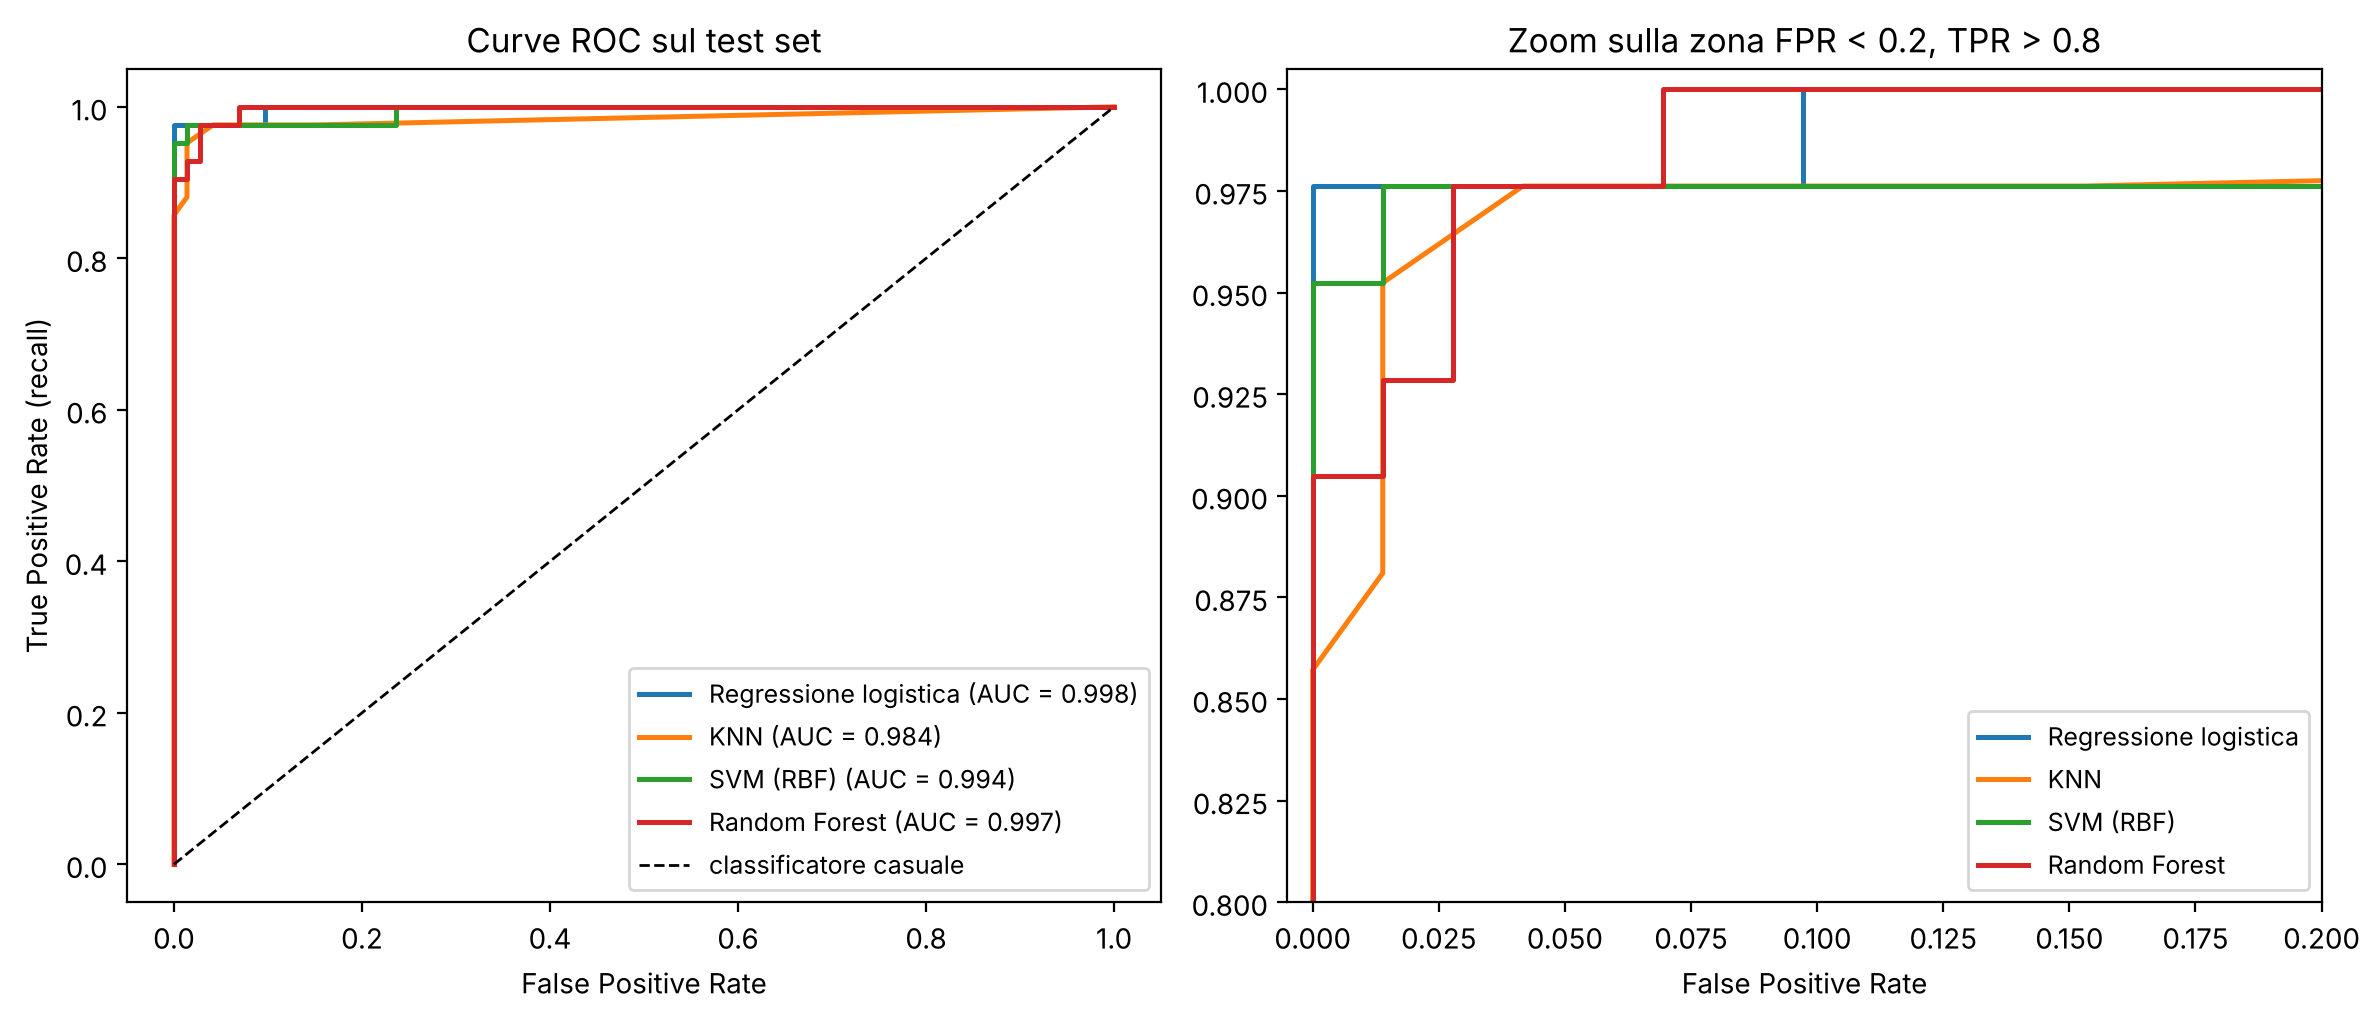

In [13]:
# le curve finiscono tutte schiacciate in alto a sinistra, quindi a destra metto uno zoom
fig, (ax, zoom) = plt.subplots(1, 2, figsize=(12, 5.2))

for nome, m in migliori.items():
    s = score_positivo(m, X_test_s)
    fpr, tpr, _ = roc_curve(y_test, s)
    ax.plot(fpr, tpr, lw=1.8, label=f"{nome} (AUC = {roc_auc_score(y_test, s):.3f})")
    zoom.plot(fpr, tpr, lw=1.8, label=nome)

ax.plot([0, 1], [0, 1], "k--", lw=1, label="classificatore casuale")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (recall)")
ax.set_title("Curve ROC sul test set")
ax.legend(loc="lower right", fontsize=9)

zoom.set_xlim(-0.005, 0.2)
zoom.set_ylim(0.8, 1.005)
zoom.set_xlabel("False Positive Rate")
zoom.set_title("Zoom sulla zona FPR < 0.2, TPR > 0.8")
zoom.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("figure/roc_shallow.png", dpi=150)
plt.show()

Quasi tutti gli errori sono maligni classificati come benigni. Per curiosità guardo cosa succederebbe abbassando la soglia di decisione (solo per capire: la soglia non va scelta guardando il test).

In [14]:
for nome in ["Regressione logistica", "Random Forest"]:
    p = migliori[nome].predict_proba(X_test_s)[:, 1]
    for soglia in [0.5, 0.4, 0.3]:
        cm = confusion_matrix(y_test, (p >= soglia).astype(int))
        print(f"{nome:22s} soglia {soglia}:  maligni trovati {cm[1, 1]}/{y_test.sum()}, "
              f"falsi positivi {cm[0, 1]}")

Regressione logistica  soglia 0.5:  maligni trovati 40/42, falsi positivi 0
Regressione logistica  soglia 0.4:  maligni trovati 41/42, falsi positivi 0
Regressione logistica  soglia 0.3:  maligni trovati 41/42, falsi positivi 5
Random Forest          soglia 0.5:  maligni trovati 38/42, falsi positivi 1
Random Forest          soglia 0.4:  maligni trovati 39/42, falsi positivi 1
Random Forest          soglia 0.3:  maligni trovati 41/42, falsi positivi 2


## 6. Opzione a): rete neurale

Uso un percettrone multistrato con Keras, addestrato sugli **stessi** `X_train_s`, `X_val_s`, `X_test_s` usati sopra. Il validation set serve per l'early stopping: se la loss sul validation non migliora per 20 epoche mi fermo e recupero i pesi migliori.

La rete è volutamente piccola: con 341 campioni di training una rete grande andrebbe in overfitting quasi subito.

In [15]:
import tensorflow as tf
import keras
from keras import layers

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()   # per avere risultati ripetibili

rete = keras.Sequential([
    layers.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
rete.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
             loss="binary_crossentropy",
             metrics=["accuracy"])
rete.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)

storia = rete.fit(X_train_s, y_train.values,
                  validation_data=(X_val_s, y_val.values),
                  epochs=300, batch_size=16, callbacks=[stop], verbose=0)

h = storia.history
epoca_migliore = int(np.argmin(h["val_loss"]) + 1)
print("Epoche eseguite:", len(h["loss"]), "- pesi ripristinati dall'epoca", epoca_migliore)
print(f"val_loss migliore = {min(h['val_loss']):.4f}, "
      f"val_accuracy a quell'epoca = {h['val_accuracy'][epoca_migliore - 1]:.3f}")

Epoche eseguite: 46 - pesi ripristinati dall'epoca 26
val_loss migliore = 0.0744, val_accuracy a quell'epoca = 0.965


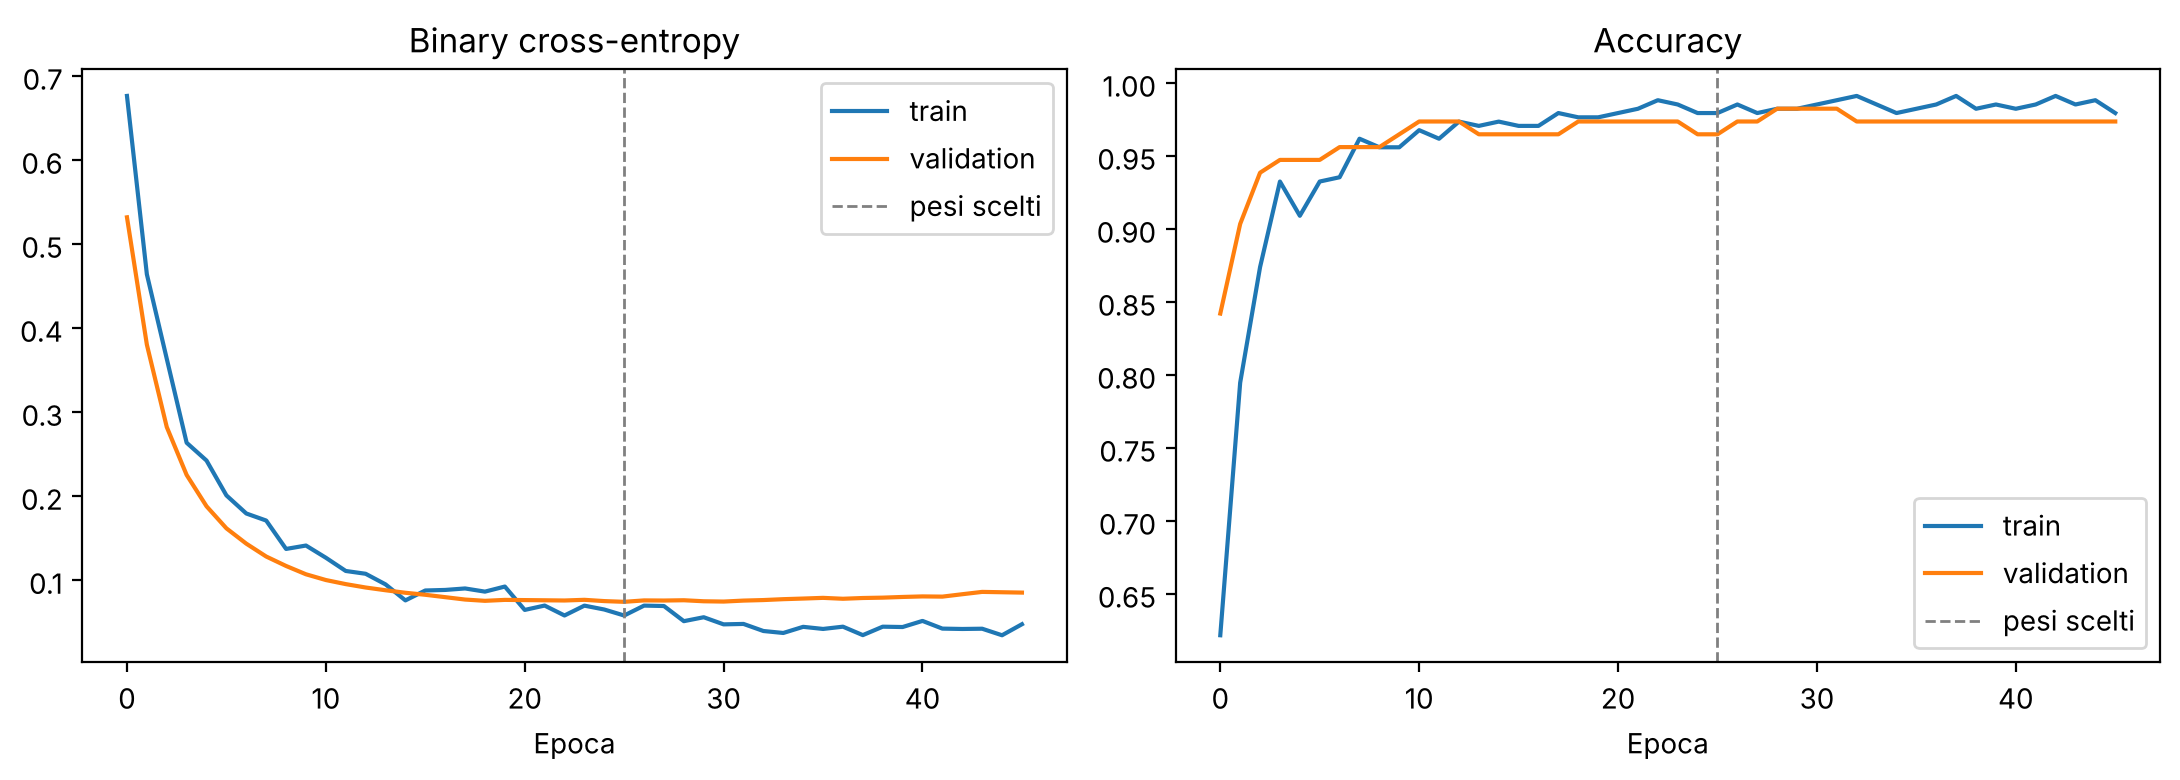

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metrica, titolo in [(axes[0], "loss", "Binary cross-entropy"),
                            (axes[1], "accuracy", "Accuracy")]:
    ax.plot(h[metrica], label="train")
    ax.plot(h["val_" + metrica], label="validation")
    ax.axvline(epoca_migliore - 1, ls="--", color="grey", lw=1, label="pesi scelti")
    ax.set_xlabel("Epoca")
    ax.set_title(titolo)
    ax.legend()
plt.tight_layout()
plt.savefig("figure/mlp_training.png", dpi=150)
plt.show()

In [18]:
p_test = rete.predict(X_test_s, verbose=0).ravel()
y_pred_rete = (p_test >= 0.5).astype(int)
risultati_test["Rete neurale (MLP)"] = valuta(y_test, y_pred_rete, p_test)

tabella = pd.DataFrame(risultati_test).T.round(3)
tabella

,Accuracy,Precision,Recall,F1,ROC AUC
Regressione logistica,0.982,1.000,0.952,0.976,0.998
KNN,0.947,0.974,0.881,0.925,0.984
SVM (RBF),0.974,0.976,0.952,0.964,0.994
Random Forest,0.956,0.974,0.905,0.938,0.997
Rete neurale (MLP),0.974,1.000,0.929,0.963,0.994


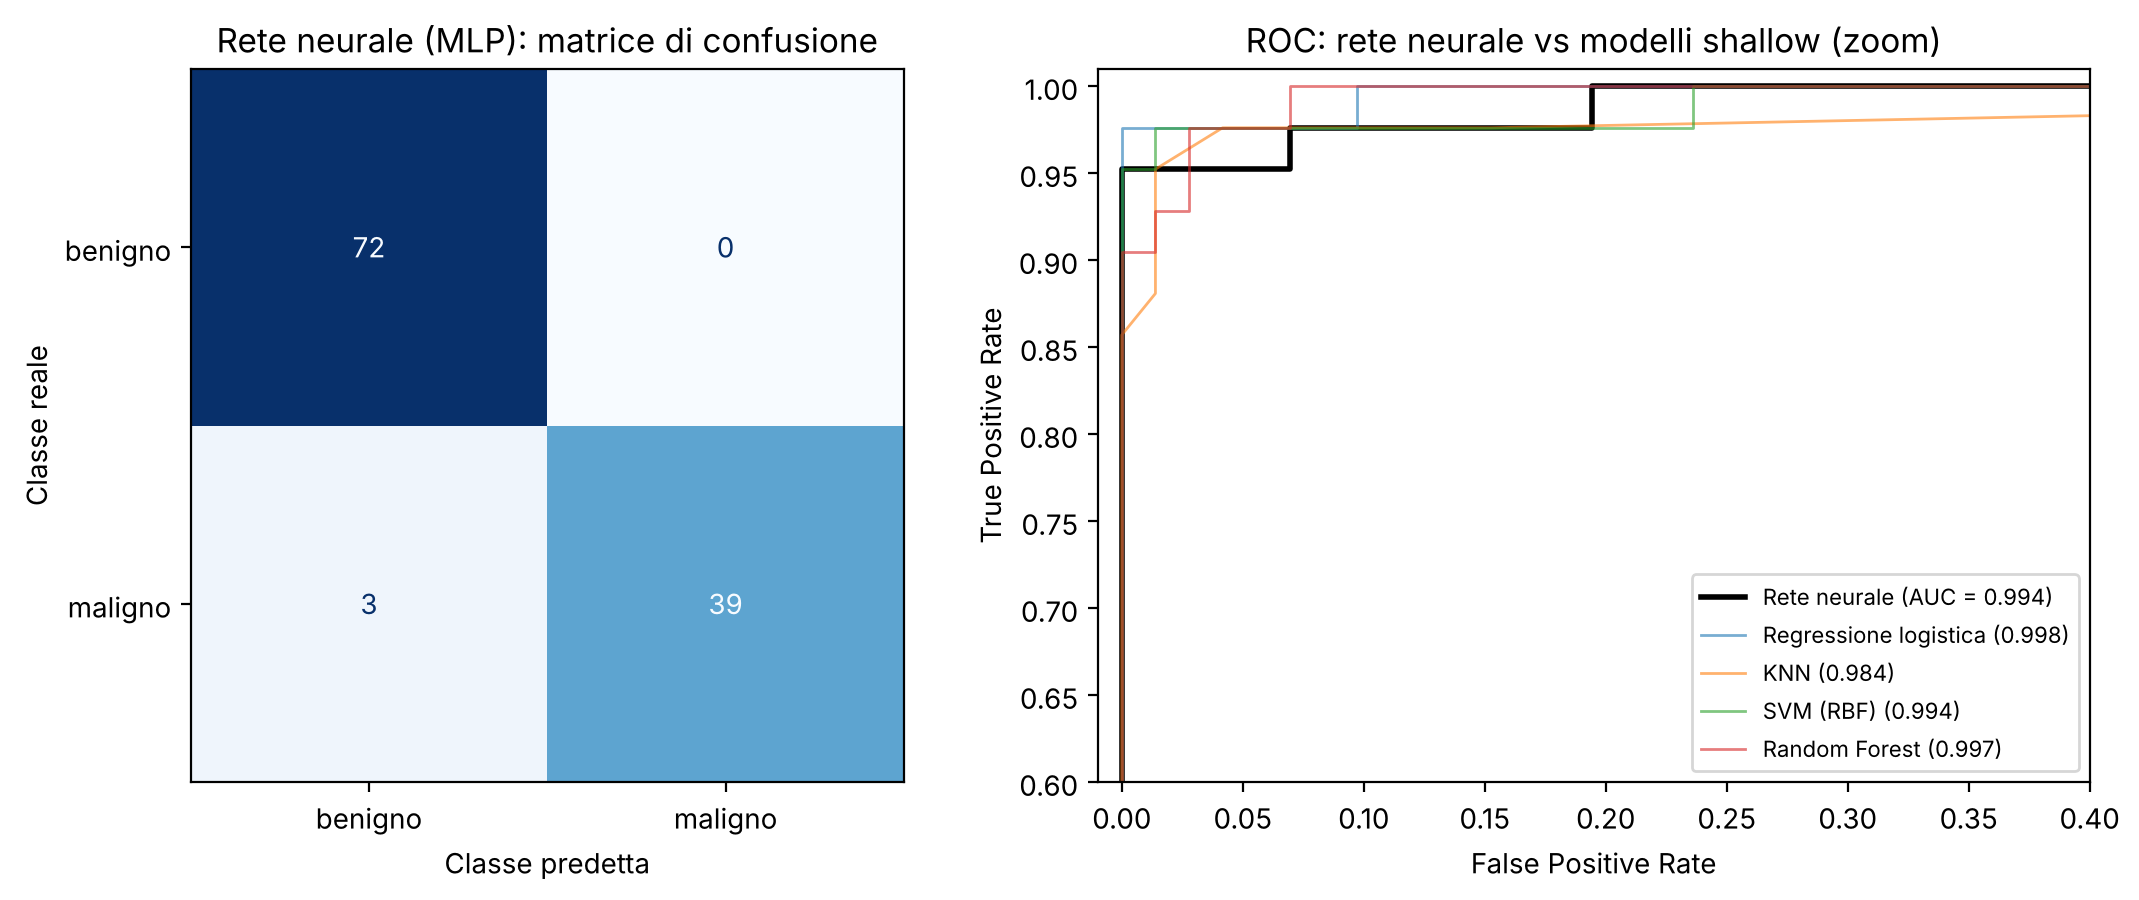

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rete, display_labels=["benigno", "maligno"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Rete neurale (MLP): matrice di confusione")
axes[0].set_xlabel("Classe predetta")
axes[0].set_ylabel("Classe reale")

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, lw=2, color="black",
             label=f"Rete neurale (AUC = {roc_auc_score(y_test, p_test):.3f})")
for nome, m in migliori.items():
    s = score_positivo(m, X_test_s)
    f, t, _ = roc_curve(y_test, s)
    axes[1].plot(f, t, lw=1, alpha=0.6, label=f"{nome} ({roc_auc_score(y_test, s):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set_xlim(-0.01, 0.4)
axes[1].set_ylim(0.6, 1.01)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC: rete neurale vs modelli shallow (zoom)")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("figure/mlp_valutazione.png", dpi=150)
plt.show()

Ultima verifica: i campioni del test sbagliati sono gli stessi per tutti i modelli o ognuno sbaglia i suoi?

In [20]:
predizioni = {nome: m.predict(X_test_s) for nome, m in migliori.items()}
predizioni["Rete neurale (MLP)"] = y_pred_rete
errori = pd.DataFrame({nome: (p != y_test.values) for nome, p in predizioni.items()},
                      index=y_test.index)

quanti = errori.sum(axis=1)
print("Campioni sbagliati da almeno un modello:", (quanti > 0).sum(), "su", len(y_test))
print("Sbagliati da tutti e 5:", (quanti == 5).sum())
dettaglio = errori[quanti > 0].astype(int)
dettaglio.insert(0, "classe reale", y_test[quanti > 0].map({0: "benigno", 1: "maligno"}))
dettaglio["p(maligno) rete"] = np.round(p_test[(quanti > 0).values], 3)
dettaglio

Campioni sbagliati da almeno un modello: 9 su 114
Sbagliati da tutti e 5: 1


,classe reale,Regressione logistica,KNN,SVM (RBF),Random Forest,Rete neurale (MLP),p(maligno) rete
99,maligno,0,1,0,0,0,0.823
73,maligno,1,1,1,1,1,0.020
208,benigno,0,1,1,0,0,0.202
86,maligno,0,0,0,1,0,0.923
100,maligno,0,1,0,1,0,0.893
385,maligno,0,1,0,1,0,0.792
190,maligno,0,0,0,0,1,0.125
128,benigno,0,0,0,1,0,0.333
205,maligno,1,1,1,0,1,0.496


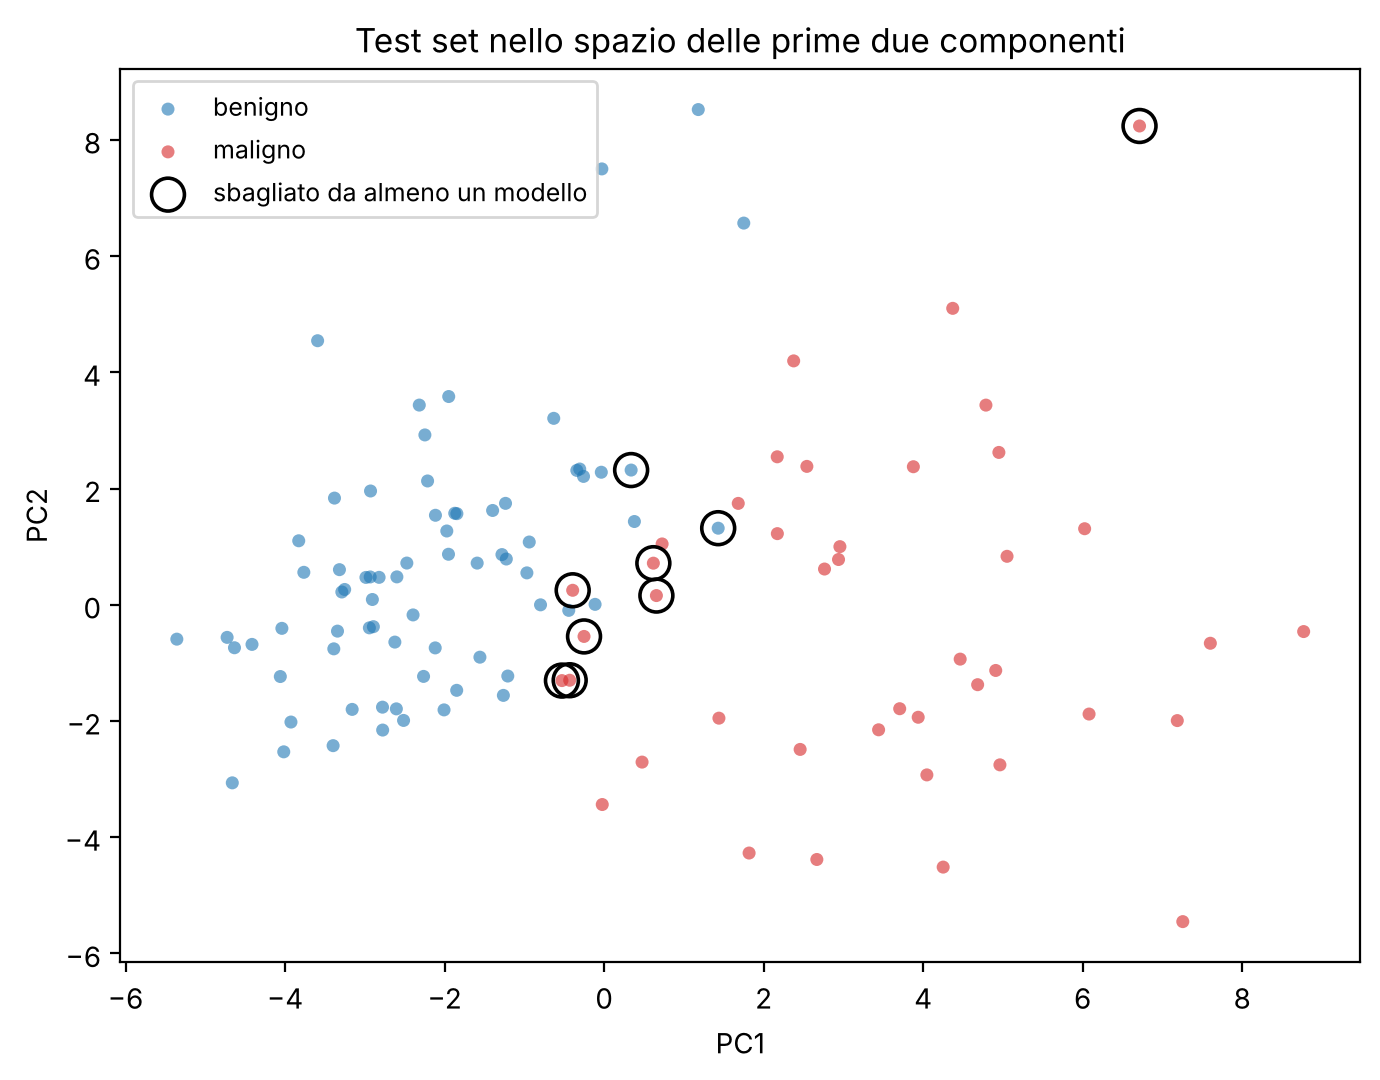

In [21]:
Z_test = pca.transform(X_test_s)

fig, ax = plt.subplots(figsize=(7, 5.5))
for classe, colore, etichetta in [(0, "tab:blue", "benigno"), (1, "tab:red", "maligno")]:
    m = y_test.values == classe
    ax.scatter(Z_test[m, 0], Z_test[m, 1], s=22, alpha=0.6, c=colore, label=etichetta,
               edgecolors="none")
sbagliati = (quanti > 0).values
ax.scatter(Z_test[sbagliati, 0], Z_test[sbagliati, 1], s=140, facecolors="none",
           edgecolors="black", linewidths=1.3, label="sbagliato da almeno un modello")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Test set nello spazio delle prime due componenti")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("figure/errori_pca.png", dpi=150)
plt.show()

C'è un punto strano: il maligno isolato in alto a destra (indice 190) è lontanissimo dalla zona di confine, eppure la rete lo sbaglia. Guardo quanto sono estremi i suoi valori rispetto al training set.

In [22]:
z_190 = pd.Series(X_test_s[y_test.index.get_loc(190)], index=X.columns)
top6 = z_190.abs().sort_values(ascending=False).head(6)
max_train = pd.Series(np.abs(X_train_s).max(axis=0), index=X.columns)

print(pd.DataFrame({"|z| campione 190": top6, "max |z| nel training": max_train[top6.index]}).round(2))

                         |z| campione 190  max |z| nel training
compactness error                    6.22                  4.58
worst compactness                    4.33                  4.36
symmetry error                       3.62                  6.91
worst fractal dimension              3.58                  5.24
worst symmetry                       3.56                  5.87
fractal dimension error              3.35                  8.01


## Conclusioni

I commenti completi sono nella relazione. In breve: su questo dataset tutti i modelli raggiungono valori molto alti; le differenze tra uno e l'altro si giocano su pochissimi campioni del test, che sono soprattutto i casi che stanno nella zona di sovrapposizione tra le due classi già visibile nel grafico della PCA.